Dimensiones iniciales: (398, 9)


,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


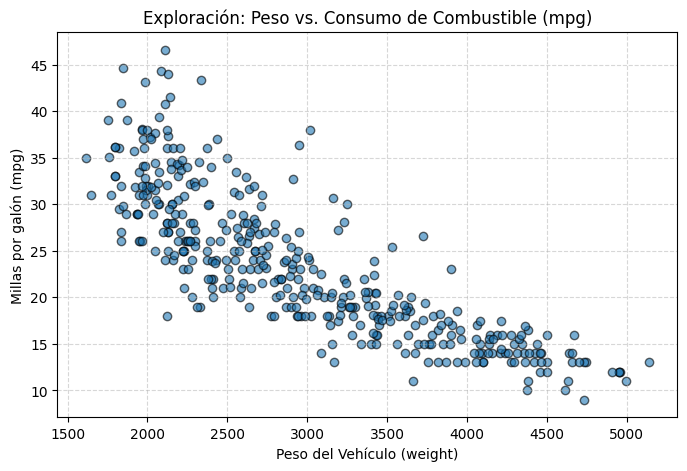

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset de automóviles
df_auto = pd.read_csv('Automobile.csv')

# Verificar columnas y primeras filas
print(f"Dimensiones iniciales: {df_auto.shape}")
display(df_auto.head())

# Seleccionar variables para el análisis y limpiar posibles nulos
df_reg = df_auto[['weight', 'mpg']].dropna()

# Gráfico de dispersión exploratorio
plt.figure(figsize=(8, 5))
plt.scatter(df_reg['weight'], df_reg['mpg'], color='#1f77b4', alpha=0.6, edgecolors='k')
plt.title("Exploración: Peso vs. Consumo de Combustible (mpg)")
plt.xlabel("Peso del Vehículo (weight)")
plt.ylabel("Millas por galón (mpg)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [2]:
from sklearn.model_selection import train_test_split

# Variables de entrada (X) y objetivo continua (y)
X = df_reg[['weight']]
y = df_reg['mpg']

# Partición 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de prueba: {len(X_test)}")

Observaciones de entrenamiento: 318
Observaciones de prueba: 80


Pendiente (alfa): -0.0078
Intersección (beta): 46.7821


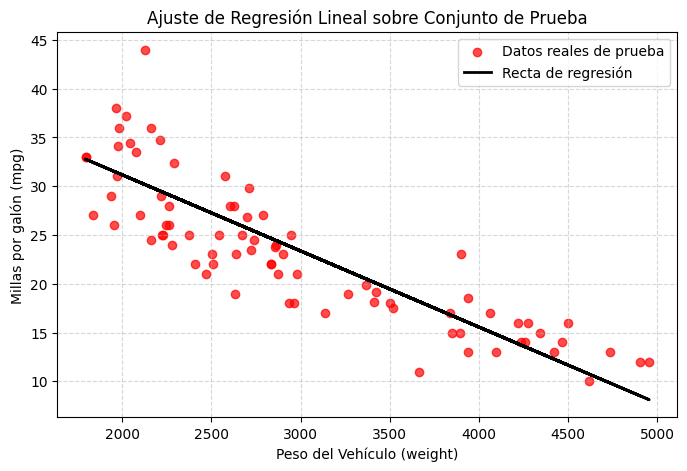

In [3]:
from sklearn.linear_model import LinearRegression

# Crear y entrenar el modelo de Regresión Lineal
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# Coeficientes obtenidos
print(f"Pendiente (alfa): {modelo_lineal.coef_[0]:.4f}")
print(f"Intersección (beta): {modelo_lineal.intercept_:.4f}")

# Predicción sobre los datos de prueba
y_pred_test = modelo_lineal.predict(X_test)

# Gráfico del ajuste sobre el conjunto de prueba
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='red', alpha=0.7, label='Datos reales de prueba')
plt.plot(X_test, y_pred_test, color='black', linewidth=2, label='Recta de regresión')
plt.title("Ajuste de Regresión Lineal sobre Conjunto de Prueba")
plt.xlabel("Peso del Vehículo (weight)")
plt.ylabel("Millas por galón (mpg)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [4]:
import sklearn.metrics as sm

# Cálculo de las métricas explicadas en la clase
mae = sm.mean_absolute_error(y_test, y_pred_test)
mse = sm.mean_squared_error(y_test, y_pred_test)
medae = sm.median_absolute_error(y_test, y_pred_test)
evs = sm.explained_variance_score(y_test, y_pred_test)
r2 = sm.r2_score(y_test, y_pred_test)

print(f"Error absoluto medio (MAE): {mae:.2f}")
print(f"Error cuadrático medio (MSE): {mse:.2f}")
print(f"Error absoluto mediano (MedAE): {medae:.2f}")
print(f"Puntuación de varianza explicada: {evs:.2f}")
print(f"Puntuación R2: {r2:.2f}")

Error absoluto medio (MAE): 3.12
Error cuadrático medio (MSE): 14.89
Error absoluto mediano (MedAE): 2.67
Puntuación de varianza explicada: 0.73
Puntuación R2: 0.72
